# OpenFOAM


  OpenFOAM is an open-source software framework primarily designed for solving complex problems involving computational fluid dynamics (CFD). It provides a versatile and extensible platform for simulating and analyzing fluid flow, heat transfer, chemical reactions, and other related phenomena. OpenFOAM stands for “Open Field Operation and Manipulation” and is developed and maintained by the OpenFOAM Foundation and a global community of contributors 

Specifically ,this OpenFOAM tutorial aims to guide users in solving intricate chemical equations for all species involved,encompassing fuel, oxidizer, intermediate products, and final product species. Additionally, it aims to educate users on effective post-processing techniques for interpreting and enhancing the analysis of simulation results.

Utilize the OpenFoam tutorial to acquaint yourself with the drill case scenarios provided [here](https://www.cfd.at/sites/default/files/tutorialsV7/OFTutorialSeries.pdf), The skills you acquire from this tutorial will be invaluable in designing and developing future energy conversion systems.

Here are some of the most important folders and files you'll typically find in an OpenFOAM case directory:

### 0 Directory

To begin creating an OpenFOAM case, defining the properties and initial conditions in the "0" directory is important. This includes setting up the initial and boundary conditions, which are crucial for accurately simulating the behavior of fluid flow, heat transfer, or other phenomena within your computational domain. Within this directory, you can access various general files such as Temperature ("T"), Velocity ("U"), and Pressure ("P").

- `dimensions [0 1 -1 0 0 0 0 ]` This line specifies the dimensions of the physical quantities being simulated.It is typically used to ensure that the units of the variables in the simulation are consistent with the physical world.The numbers in the brackets represent exponents for [different dimensions](https://doc.cfd.direct/openfoam/user-guide-v6/basic-file-format) (eg.lenght mass time etc). In this case, it suggests that the simulation is dealing with velocity(1) and it has dimensions of L/T(length per time ).  
- `internalField`Sets the initial values for flow variables such as velocity, pressure, and temperature within the domain. This initializes the simulation with a starting state.
- `boundaryFeild` is essential in simulating fluid flow-bounds interaction. It guarantees accurate flow behavior at domain boundaries
- `outlet` The outlet boundary condition specifies how fluid is treated as it leaves the simulation domain, by defining variables such as pressure, velocity, and turbulence parameters to reflect expected behavior
- `topAndBottom` The conditions of frontAndBack and topAndBottom are utilized to determine the behavior of the flow at the boundaries of the simulation domain, including the front, back, top, and bottom. These conditions can be adjusted to different values, like fixed values or empty conditions, depending on the specific problem being simulated. This allows for the simulation of a range of scenarios.

```/*--------------------------------*- C++ -*----------------------------------*\
| =========                 |                                                 |
| \\      /  F ield         | OpenFOAM: The Open Source CFD Toolbox           |
|  \\    /   O peration     | Version:  v2012                                 |
|   \\  /    A nd           | Website:  www.openfoam.com                      |
|    \\/     M anipulation  |                                                 |
\*---------------------------------------------------------------------------*/
FoamFile
{
    version     2.0;
    format      ascii;
    class       volVectorField;
    object      U;
}
// * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * //

dimensions      [0 1 -1 0 0 0 0];

internalField   uniform (0 0 0);

boundaryField
{
    fuel
    {
        type            fixedValue;
        value           uniform (0.39 0 0);
    }

    outlet
    {
        type            pressureInletOutletVelocity;
        value           $internalField;
    }

    topAndBottom
    {
        type            fixedValue;	
	value		uniform 0;
    }

    frontAndBack
    {
        type            empty;
    }
}


// ************************************************************************* //
```

### blockMesh

BlockMesh assigns boundary conditions to the mesh faces, defining how the flow interacts with the domain boundaries. This step is crucial for CFD simulations, as it dictates how physical properties, such as velocity and pressure, behave at boundaries.

```
/*--------------------------------*- C++ -*----------------------------------*\
| =========                 |                                                 |
| \\      /  F ield         | OpenFOAM: The Open Source CFD Toolbox           |
|  \\    /   O peration     | Version:  v2012                                 |
|   \\  /    A nd           | Website:  www.openfoam.com                      |
|    \\/     M anipulation  |                                                 |
\*---------------------------------------------------------------------------*/
FoamFile
{
    version     2.0;
    format      ascii;
    class       dictionary;
    object      blockMeshDict;
}
// * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * //

scale   1;

vertices
(
    (0.0  -0.015 -0.01)
    (0.02 -0.015 -0.01)
    (0.02  0.015 -0.01)
    (0.0   0.015 -0.01)
    (0.0  -0.015  0.01)
    (0.02 -0.015  0.01)
    (0.02  0.015  0.01)
    (0.0   0.015  0.01)
);

blocks
(
    hex (0 1 2 3 4 5 6 7) (400 300 1) simpleGrading (1 1 1)
);

edges
(
);

boundary
(
    fuel
    {
        type patch;
        faces
        (
            (0 4 7 3)
        );
    }
    outlet
    {
        type patch;
        faces
        (
            (1 2 6 5)
        );
    }
    topAndBottom
    {
        type patch;
        faces
        (
            (0 1 5 4)
            (7 6 2 3)
        );
    }
    frontAndBack
    {
        type empty;
        faces
        (
            (4 5 6 7)
            (0 3 2 1)
        );
    }
);

mergePatchPairs
(
);

// ************************************************************************* //
```

- `scale 1` The scale of 1 indicates that the mesh dimensions are in their original units and not scaled.
- `vertices` In the vertices section, there are eight coordinates listed that define the corners of the simulation domain. These coordinates form a rectangular block that is used as the computational domain. Each vertex is represented as (x y z), with the origin being (0, 0, 0).
- `blocks` In this section, we define the mesh block using eight vertices previously defined. It will be a hexahedral (hex) mesh block with (0 1 2 3 4 5 6 7) list defining the vertices used to create the block's faces. Additionally, (400 300 1) specifies the number of cells in the x, y, and z directions within this block. The uniform mesh grading (cell size variation) in all directions is indicated by simpleGrading (1 1 1).
- `Edges` The edges section is currently empty. It can be used to add more edges for mesh refinement.
- __Boundary__
 The boundary section defines the boundary conditions for different parts of the domain. It includes four boundary patches: fuel, outlet, topAndBottom, and frontAndBack
 - `fule` It represents the boundary where fuel enters the domain. It's defined as a patch type, and the faces associated with it are specified as (0 4 7 3), indicating the vertices that make up this boundary.
 - `outlet` It represents the boundary where flow exits the domain. Like fuel, it's a patch type, and its associated faces are defined as (1 2 6 5).
 - `topAndBottom` It represents the top and bottom boundaries of the domain. It's a patch type with two sets of faces, each specified by a list of vertices.
 - `frontAndBack` Itrepresents the front and back boundaries and is set as empty, indicating that there are no specific boundary conditions applied to these regions.
 - ` mergePatchPairs`In this section is empty in this configuration, but it is used to specify pairs of mesh patches that should be merged together.

### controlDict

The time from where simulation starts (startFrom), the time when the simulation finishes (stopAt), the time step (deltaT), the data saving interval (writeInterval), the saved data file format (writeFormat), the saved file data precision (writePrecision), and also if changing the files during the run can affect the run or not (runTimeModifiable) are set in this file.

The revised tutorial case introduces a deeper level of detail, particularly in the context of the elbow case. Notably, the alteration involves transitioning the flow pattern to counterflow, a change that will be elaborated upon in greater depth below.

Copy the elbow case from $FOAM_TUTORIALS/incompressible/icoFoam/elbow

In 0 directory change the CH4 boundary conditions

``` 
{
    version     2.0;
    format      ascii;
    class       volScalarField;
    object      CH4;
}
// * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * //

dimensions [0 0 0 0 0 0 0];
internalField uniform 0.0;
boundaryField
{
 wall-4
 {
 type zeroGradient;
 }
 velocity-inlet-5
 {
 type fixedValue;
 value uniform 0; //no CH4 at this inlet
 }
 velocity-inlet-6
 {
 type fixedValue;
 value uniform 0.5; //50% CH4 mass fraction at this inlet
 }
 pressure-outlet-7
 {
 type zeroGradient;
 }
 wall-8
 {
 type zeroGradient;
 }
 frontAndBackPlanes
 {
 type empty;
 }
}
// ************************************************************************* // 
```

In the elbow code block, there are inlet and wall boundary conditions defined for different patches. To perform counterFlow, change the boundary conditions to four, including "fuel," "outlet," "topAndBottom," and "frontAndBack."

```
/*--------------------------------*- C++ -*----------------------------------*\
| =========                 |                                                 |
| \\      /  F ield         | OpenFOAM: The Open Source CFD Toolbox           |
|  \\    /   O peration     | Version:  v2012                                 |
|   \\  /    A nd           | Website:  www.openfoam.com                      |
|    \\/     M anipulation  |                                                 |
\*---------------------------------------------------------------------------*/
FoamFile
{
    version     2.0;
    format      ascii;
    class       volScalarField;
    object      CH4;
}
// * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * //

dimensions      [0 0 0 0 0 0 0];

internalField   uniform 0;

boundaryField
{
    fuel
    {
        type            codedFixedValue;
        value           uniform 0;
    redirectType    rampedFixedValue;
    
    code                                           //this code calculates the value of the "CH4" variable based on the vertical                                                      position (y) within a specified range and ensures that the calculated value                                                        falls within predefined minimum and maximum limits// 
    #{
    
    const scalar y = this->patch().centroid().y(); 
    const scalar minValue = -0.015;
    const scalar maxValue = 0.015;
    const scalar minCH4 = 0.633;
    const scalar maxCH4 = 1;

    scalar value = minCH4 + (maxCH4 - minCH4) * (y - minValue) / (maxValue - minValue);
    value = fmax(minCH4, fmin(maxCH4, value));

    operator== value;
    

    #};
    }

    outlet
    {
        type            fixedValue;
        value           uniform 0;
    }

   topAndBottom
    {
        type            inletOutlet;
        inletValue      uniform 0;
        value           uniform 0;
    }

    frontAndBack
    {
        type            empty;
    }
}


// ************************************************************************* //
```


Likewise, please adjust the boundary conditions for the remaining files within the "0" directory, including "CO2," "H2O," "N2," and "O2," and modify the temperature to either 2000 degrees or your desired temperature.

# PyFLUT Tutorials

For the Development of a tutorial for simulating future sustainable energy conversion systems, PyFLUT plays a key role in differentiating the results for Tabulated chemistry prespective. 

Major practices involving PyFLUT:
- ULF Solver and Files
- Table creation from calcualtions 

For in depth understanding of the project, PyFLUT and effectively utilize it, its major role is to roust around into the vital topics:
 - Understanding laminar burning velocity in relation with equivalence ratio.
 - Evaluating the variation of laminar burning velocity with blending ratio.
 - Calculating the extinction limits for premixed counterflow. 
 
 The input files: deals with 
 - fp_setup.ulf: initial conditions, boundary conditions, parameters needed for flame propagation initiation.
 - fp_template.ulf: template file for flame propagation.
 - cf_stag_setup.ulf: initial conditons and parameters needed for counter flow flame.
 - cf_stag_template.ulf: template file for counterflow flame.
 - nh3_stagni_2020.xml: thermodynamics data, reaction rate constants, specifics related to ammonia's role.
 
 are related to the ULFsolver. These files cover all the required data with in it.

Source: 
 Click [here](https://git.rwth-aachen.de/stfs/codes/pyflut/-/wikis/home)  ,
 [here](https://stfs.pages.rwth-aachen.de/codes/pyflut/content/00_intro/intro.html).
 for official documentaion with respect to the above description in detail. 
 
 Note: Can only access these links with authorization from the administrator

# Example case: Diffusion FLUT Tutorial

### Objective:
To create a FLUT(Flamelet lookup table) using PyFLUT and ULF solver.

### Case Preparation:
First step is to start by creating a new directory -DiffusionFLUTTutorial and add Template, DiffusionRunner,input.yml, flamelet_mixtureEntries.ulf, setup files to it. 
Make sure to select the PyFLUT environment as kernel. 
To do it in the terminal, load the anaconda module and activate pyflut.

### Case Setup:
Since we have all the files to run Diffusion case using ULF, visualise the domain as the centerline of a counterflow burner.

#### Defining Fuel and Oxidiser 
In this case, the fuel and oxidiser are CH4 and air both at a temperature of 300K and at atmospheric pressure.

In [1]:

streams = {
    'fuel':
    {
       'T': 300,
       'X':
       {
       'CH4': 1
       },
       'pressure': 101325
    },
    'oxidizer':
    {
       'T': 300,
       'X':
       {
       'O2': 0.21,
       'N2': 0.79
       },
       'pressure': 101325
    }
}

The next step is to define the settings to the solver

In [2]:
settings = {  
 
  'numerical_model': 'steady',
  'reference_file': 'flamelet_setup.ulf',
  'basename': 'sldf',
  'par_format': '{:5.4f}',
  'mechanism': 'ch4_smooke_EKT.xml',
  'key_variable': 'Z',
  'n_grid': 500,
  'recalculate_flamelets': True,
  'keys': {
    'Zst': 'ZST',
    'basename': 'RESULT_BASENAME',
    'n_grid': 'REFINE_TARGET',
    'mechanism': 'MECHANISM',
    'chist': 'CHIST',
    'pressure': 'P',
   },
  }


### Parameter Variation in Z space: 

This case is carried out in Z-space, mixture fraction Z as coordinate.
Therefore, the mixture fraction  $$Z = \frac{m_{\mathrm{fuel}}}{m_{\mathrm{fuel}}+m_{\mathrm{oxidizer}}}.$$
 
The fuel and oxidiser denote the masses from their inlets.However, even after the elements have undergone the reactions, the atomics contituents remian in the system.

Since it is not physical space, the velocity doesnt fit in the picture perfectly to adjust the mixing rate.Hence, there arrives the concept of Scalar Dissipitaion Rate $\chi$ (chi), defines as $$\chi = 2D |\nabla Z|^2.$$

This rate serves as the indicator of the rate of chamge of z. For counterflow setup, the inverse of the complementary error function can approximate  $\chi$. Scaled by one Z-$\chi$ relation. 


#### $\chi$ Profiles
To get a little more familiar with the $\chi$ profiles for different $\chi_{st}$, we'll have a brief look at them.

First we import the scipy function for the inverse error function complement and numpy.


In [3]:
from scipy.special import erfcinv
import numpy as np

Define a function for $\chi$(Z) based on the inverse error function complement.

In [4]:
def erfcinv_chist(Zst):
    return (erfcinv(2*Zst))**2

def chi_func(chi_st, Zst, Z):
    return chi_st * np.exp(2*(erfcinv_chist(Zst) - erfcinv(2*Z)**2))

Next, define a range of Z and calculate the profiles for different chi_st. Zst for methane is ca. 0.054.

In [5]:
Z = np.linspace(0,1,101)
Zst = 0.054
chi_sts = [5,10,20,30]

profiles = {} 

for chi_st in chi_sts:
    profiles[chi_st] = chi_func(chi_st,Zst,Z)  

Now, plot each profile.

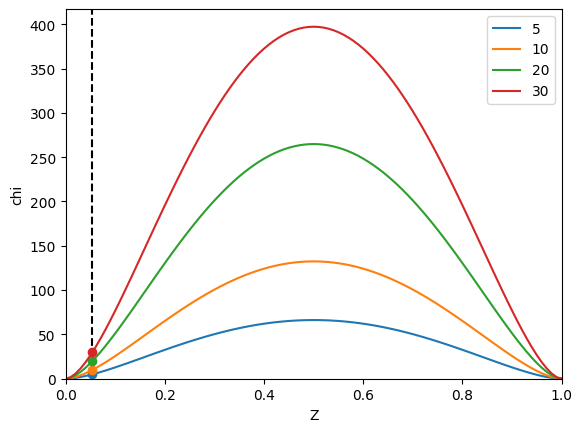

In [6]:
from matplotlib import pyplot as plt
plt.axvline(x = Zst, color = 'k',linestyle='--')
for chi_st in chi_sts:
    p = plt.plot(Z, profiles[chi_st],label=str(chi_st))
    plt.plot(Zst,chi_st, marker='o', color = p[0].get_color())
plt.ylim(0,None)
plt.xlim(0,1)
plt.legend()
plt.xlabel('Z')
plt.ylabel('chi')
plt.show()

Can also add few more values to the chi_st list and re-run.
Keep the list of $\chi_{st}$ s for the parameter variation for the table. Remember, $\chi$ is a measure for the mixing at a certain $Z$.

## Running Parameter Variation
Next step, is to define a runner with the setup established earlier (before excursion into $\chi$). 
First, pyFLUT need to be loaded, then instantiate the runner. 

In [7]:
import pyFLUT
runner = pyFLUT.runner.UlfRunner(settings=settings, yaml_streams=streams, runner_functions=[])

/shared_home/pnammi/Code/pyflut/pyFLUT/runner/_abstract.py:102: DeprecationWarning: XML_Node::build: 
The CTI and XML input file formats are deprecated and will be removed in
Cantera 3.0. Use 'cti2yaml.py' or 'ctml2yaml.py' to convert CTI or XML input
files to the YAML format. See https://cantera.org/tutorials/legacy2yaml.html
for more information.
  self.gas = ct.Solution(settings["mechanism"])


### Run the runner for a bunch of $\chi_{st}$

In [8]:
for chi_st in chi_sts:
    runner.run({'chist':chi_st})

Running temp_chist5.0000_run
End run temp_chist5.0000_run
Running temp_chist10.0000_run
End run temp_chist10.0000_run
Running temp_chist20.0000_run
End run temp_chist20.0000_run
Running temp_chist30.0000_run
End run temp_chist30.0000_run


### Looking at a single run
Now look at one of the succesful runs.
Pick one of the `sldf_chist*.ulf` files.


In [9]:
result = pyFLUT.Flame1D.read_flame('sldf_chist20.0000.ulf')
result


{'chist': 20.0}

The result object contains different fields that can be shown with `result.output_variables`.

In [10]:
result.output_variables

['Z',
 'CH2O',
 'CH3',
 'CH3O',
 'CH4',
 'CO',
 'CO2',
 'Dtherm_CH2O',
 'Dtherm_CH3',
 'Dtherm_CH3O',
 'Dtherm_CH4',
 'Dtherm_CO',
 'Dtherm_CO2',
 'Dtherm_H',
 'Dtherm_H2',
 'Dtherm_H2O',
 'Dtherm_H2O2',
 'Dtherm_HCO',
 'Dtherm_HO2',
 'Dtherm_N2',
 'Dtherm_O',
 'Dtherm_O2',
 'Dtherm_OH',
 'DthermiDefault',
 'H',
 'H2',
 'H2O',
 'H2O2',
 'HCO',
 'HO2',
 'LeZ',
 'Le_CH2O',
 'Le_CH3',
 'Le_CH3O',
 'Le_CH4',
 'Le_CO',
 'Le_CO2',
 'Le_H',
 'Le_H2',
 'Le_H2O',
 'Le_H2O2',
 'Le_HCO',
 'Le_HO2',
 'Le_N2',
 'Le_O',
 'Le_O2',
 'Le_OH',
 'LeiDefault',
 'MMean',
 'N2',
 'O',
 'O2',
 'OH',
 'T',
 'YiDefault',
 'chi',
 'cpMean',
 'h0Mean',
 'hMean',
 'lambda',
 'p',
 'reactionRate_CH2O',
 'reactionRate_CH3',
 'reactionRate_CH3O',
 'reactionRate_CH4',
 'reactionRate_CO',
 'reactionRate_CO2',
 'reactionRate_H',
 'reactionRate_H2',
 'reactionRate_H2O',
 'reactionRate_H2O2',
 'reactionRate_HCO',
 'reactionRate_HO2',
 'reactionRate_N2',
 'reactionRate_O',
 'reactionRate_O2',
 'reactionRate_OH',
 'reactio

Now, get the numpy array of a result with `result['<name of variable>']` notation. Get the numpy array of one of the variables!. for example : CO2

In [11]:
result['CO2']

array([0.        , 0.00812695, 0.0121891 , 0.01624914, 0.01827763,
       0.02030471, 0.02131756, 0.02232987, 0.02334157, 0.02435259,
       0.02536283, 0.0263722 , 0.0273806 , 0.02838791, 0.02939403,
       0.03039882, 0.03140216, 0.03240389, 0.03340388, 0.03440196,
       0.03539797, 0.03639174, 0.03738307, 0.03837178, 0.03935767,
       0.04034052, 0.04083072, 0.04132009, 0.04180857, 0.04229616,
       0.04278282, 0.04326851, 0.0437532 , 0.04423687, 0.04471948,
       0.045201  , 0.04568139, 0.04616062, 0.04663866, 0.04711546,
       0.04759099, 0.04806522, 0.04853811, 0.04900961, 0.0494797 ,
       0.04994833, 0.05041547, 0.05088107, 0.05134509, 0.0518075 ,
       0.05226825, 0.0527273 , 0.05318461, 0.05364014, 0.05409384,
       0.05454568, 0.0549956 , 0.05544357, 0.05588954, 0.05633347,
       0.05677532, 0.05721503, 0.05765257, 0.05808789, 0.05852094,
       0.05895169, 0.05938008, 0.05980607, 0.06022963, 0.06065069,
       0.06106922, 0.06148517, 0.0618985 , 0.06230916, 0.06271

Use the plotdate function for a single result, specify X and Y variable. 

<Axes: xlabel='Z', ylabel='chi'>

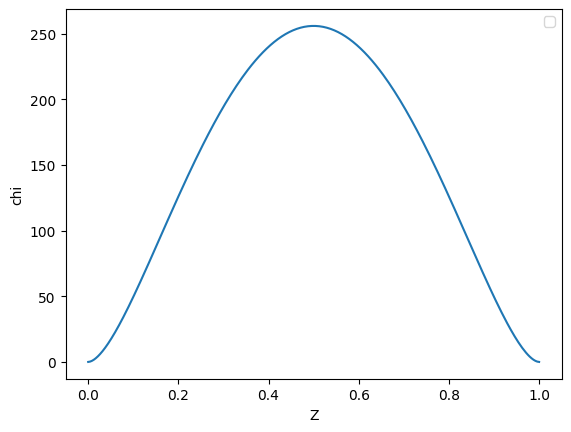

In [12]:
result.plotdata('Z','chi')

## Creating a FLUT
After succesfully running all the cases,assemble them into a FLUT. In the first step, all simulations will be read and mapped to a common grid in Z direction. Then they can be composed into a table along the coordinates Z and chist. First we'll have another look at our directory.

In [13]:
flut = pyFLUT.Flut.read_pyflut_run(prefix=runner.settings['basename'])

Read ULF files
Key variable is not defined by user. The first variable defined in ulf files is used as key variable: Z
Input data have different input grids. Interpolate the data to the same grid
Order results


Now, the FLUT contains the table of simulations. exporting it to a jupyter cell will show the table. 

In [14]:
flut


Variable      Min    Max    N
----------  -----  -----  ---
chist           5     30    4
Z               0      1  746

<Axes: xlabel='Z', ylabel='T'>

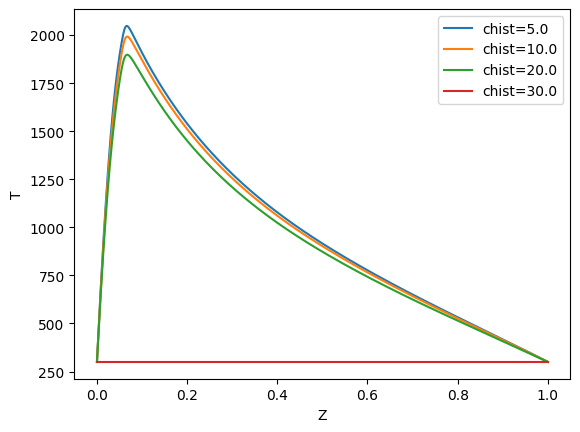

In [15]:
flut.plotdata('Z', 'T', chist=flut.input_dict['chist'])

<Axes: xlabel='Z', ylabel='CO2'>

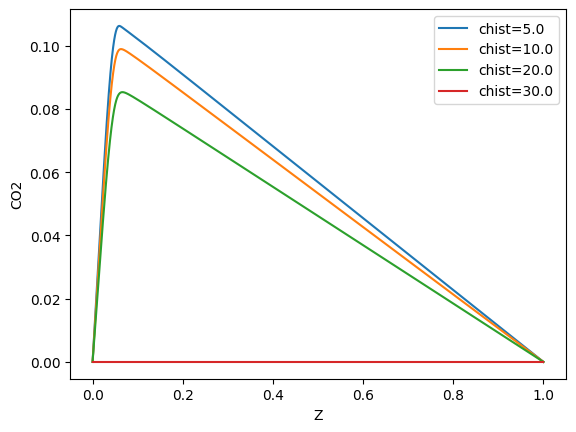

In [16]:
flut.plotdata('Z', 'CO2', chist=flut.input_dict['chist'])

Try to plot a few other species above. E.g. CO, H2, OH, H2O.

If not, go back up and increase the final grid resolution in the settings and re-run all cells.Make sure that the flamelets are actually calculated again.

### Post-processing the FLUT
We calculated the diffusion flames between Z=0 and Z=1 because we expect to see pure fuel to pure oxidizer in our simulation, varied the *scalar dissipation rate* $\chi_{st}$, as expect to have different mixing strengths in our simulation e.g. due to turbulence or strain.
Since, $\chi_{st}$ is difficult to calculate. Therefore, another variable is used instead. This variable needs to be distinct for every Z and chi_st value. i.e. if we plot it over Z for all chi_st, the lines must not overlap.  After combining multiple species, there exists combinations, map $\chi_st$ to the combination species thus called Progress variables or PV or yc. 


For methane-air flames a combination of CO2, CO, H2O and H2 works very well. Hence, in the next step, map to that.

In [17]:
flut.calc_progress_variable(along_variable='chist',definition_dict={'CO2':1,'CO':1,'H2O':1,'H2':1} )

Have a look at the PV over Z for different $\chi_{st}$.

<Axes: xlabel='Z', ylabel='yc'>

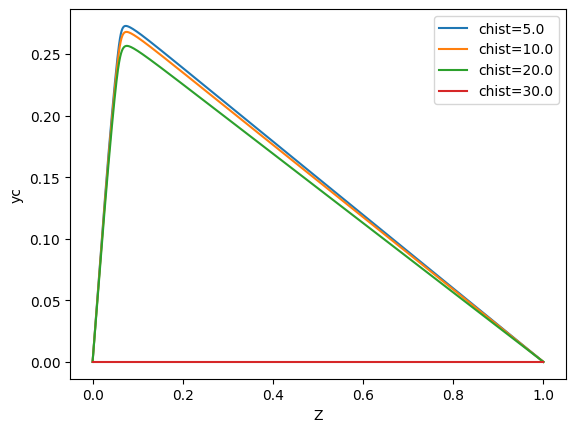

In [18]:
flut.plotdata('Z', 'yc', chist=flut.input_dict['chist'])

Since the lines dont overlap, each state is distinct and can be mapped from $\chi_{st}$ to the normalised PV.
The normalized PV is also called cc and is calculated as follows (with yc for PV):
$$ cc = \frac{yc - yc_{\mathrm{min}}}{yc_{\mathrm{max}} - yc_{\mathrm{min}}} $$

In [19]:
flut = flut.map_variables(from_inp='chist',to_inp='cc', n_points=101)


In [20]:
flut


Variable      Min    Max    N
----------  -----  -----  ---
cc              0      1  101
Z               0      1  746

Finally, the FLUT is ready.


### Add pure mixing
In the flame, there might be the regions, where the flame is extinguished. Therefore, make sure that this is also reflected in the table. Such regions would be characterized by pure mixing. The product species would be zero. 
Go back up and increase the highest chi_st value until, theres a straight line in the PV plot.

# The easier way

Instead of going one step after another in a jupyter notebook, define all the steps in the input.yml file. Have a look (to see the full file, open in vim in your terminal, in the VSCod file explorer or click text editor below).

In [112]:
!cat input_diffusion.yml

# YAML input setting file
streams:
  fuel:
    T: 300
    Y:
      CH4: 1
      N2: 0

  oxidizer:
    T: 300
    X:
      O2: 0.21
      N2: 0.79

pressure: 101325

parameters:
  chist:
    method: logspace
    values: [-1, 1, 8]

runner_functions:

solver:
  # Solver
  numerical_model: steady
  # Reference ulf configuration file
  reference_file: flamelet_setup.ulf
  recalculate_flamelets: false
  key_variable: Z
  # basename for new calculation
  basename: sldf
  # format of results parameters
  par_format: "{:5.4f}"
  mechanism: ch4_smooke_EKT.xml
  n_grid: 100


  # define here the keys to map pyFLUT to ULF setup
  keys:
    Zst: ZST
    basename: RESULT_BASENAME
    n_grid: REFINE_TARGET
    mechanism: MECHANISM
    chist: CHIST
    HR_factor: HR_FACTOR
    pressure: P


flut:
  pv: {CO: 1, CO2: 1, H2O: 1, H2: 1}
  pdf_integration: {pdf_direction: 'Z', n_points_var: 3, method: 'quad'} # Settings for the pdf-integration (see pyFLUT.Flut._pdf.pdf_integration)
  assemble_settings: {

Basically, this file contains all the steps we have done in the notebook (plus a few less important ones). To run all of it at once, you can activate the pyflut environement in the terminal and use the `runFLUT` utility. We'll give it a try here in the notebook.

In [ ]:
!runFLUT UlfRunner input_diffusion.yml

Note: In case of any errors re-run the cell.

### Flags
runFLUT can be started with different flags. They change the way it behaves. We'll have a look at it with the `-h` flag. h like help.

In [126]:
!runFLUT --help

usage: runFLUT [-h] [--copy-files] [-n N_P] [--hdf5] [--hdf5-cc]
               [--hdf5-cc-pp] [--files] [-d] [--pv-optimize]
               [--flamelet-config] [--output-name FILENAME] [--solver SOLVER]
               [--run-only] [-t] [--pdb] [--REDIM] [--segregated] [--raw]
               [--ML] [--EKT]
               type input

Generate a Flamelet Look-Up table using ULF

positional arguments:
  type                  Runner: AbstractBaseRunner CanteraRunner UlfRunner;or
                        available template (for --copy-files option only):
                        DiffusionRunner DiffusionHRDRunner
                        DiffusionUnsteadyIgnitionRunner
                        PflameletConstStretchRunner
                        PflameletConstStretchHnormRunner
                        PflameletConstStretchHnormIgnitionRunner
                        PflameletCurvatureRunner PremixRunner PremixPhiRunner
                        PremixHnormRunner PremixPhiHnormRunner
               

The most important ones, for now, are the `--files`, the `--hdf5-cc`, and the `--flamelet-config` flags.
- `--files` to read all the existing files may have been generated earlier
- `--hdf5-cc` to read in an existing .h5 file. This is a format that the `flut` is saved in after the post-processing
- `--flamelet-config` to export the flut for use in OpenFOAM, another .h5 file and a .bin file are created

Check it an `sldf-cc.h5` file exists and export it to OpenFOAM!

### Congratulations, the tutorial is successfully completed.